# Workstream A — Labels and cell identity
**Question:** how complete and how consistent are the labels every project builds on?

Every figure is regenerated from the cache in `data/cache/` with `eda_shared` v0.1.1-eda. No network calls.
Figures go to `figures/eda/`, numbers to `reports/eda_A_numbers.json`, the A4 list to `reports/A4_multi_superclass_types.csv`.

malecns cells run only when a `malecns_neurons_*.parquet` cache exists; until then they print a note and skip.

In [1]:
import sys, os, json, glob
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)   # config.CACHE_DIR is relative to the repo root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import config
from eda_shared.eda_helpers import add_provisional_flags, load_neuropil_table

FIG = ROOT / "figures" / "eda"; FIG.mkdir(parents=True, exist_ok=True)
REP = ROOT / "reports"; REP.mkdir(exist_ok=True)
NUM = {}                                  # every number quoted in reports/eda_A.md
COL = {"fafb": "#1D4E89", "malecns": "#B4521C"}
TYPECOL = {"central": "#7A8699", "optic": "#2E8B57", "central complex": "#C0392B"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

def save(fig, item, datasets, pop, caption):
    """File name and caption carry item, dataset, release, threshold and population."""
    rel = "-".join(REL[d] for d in datasets)
    name = f"{item}_{'-'.join(datasets)}_{rel}_{pop}_min1.png"
    if INTERIM_M and "malecns" in datasets:
        caption += " malecns INTERIM: brain = superclass not vnc_*, optic = superclass ol_* (no roiInfo yet)."
    fig.text(0.01, -0.02, caption, ha="left", va="top", fontsize=8, wrap=True, color="#444")
    fig.savefig(FIG / name, bbox_inches="tight"); plt.show()
    print("saved", name)

def pct(x):
    return round(100 * float(x), 1)

## Load the cache and add the provisional flags

In [2]:
TABLE = load_neuropil_table()
fafb = pd.read_parquet(config.CACHE_DIR / f"fafb_neurons_{config.FAFB_MATERIALIZATION}_ann{config.FAFB_ANNOTATIONS_TAG.lstrip('v')}.parquet")
fafb = add_provisional_flags(fafb, TABLE)
REL = {"fafb": str(config.FAFB_MATERIALIZATION)}
D = {"fafb": fafb}

# malecns: brain part only (in_brain == True). NERVE_CORD = malecns region values of the
# nerve cord; fill in from the malecns region list printed in 00_integration (README).
NERVE_CORD = set()
# Interim malecns (week 2 neuPrint export, no roiInfo yet): region is all 'unknown', so in_brain and is_optic
# come from the raw superclass: brain = not vnc_*, optic = ol_*. region_group stays unknown (A2, A7-1 skipped).
MALECNS_RAW = ROOT / "data" / "raw" / "malecns_neurons_raw_male-cns_v1.0.parquet"
INTERIM_M = False
m_files = sorted(glob.glob(str(config.CACHE_DIR / "malecns_neurons_*.parquet")))
HAS_M = bool(m_files)
if HAS_M:
    raw = pd.read_parquet(m_files[0])
    INTERIM_M = bool((raw["region"] == "unknown").all())
    if INTERIM_M:
        sc = pd.read_parquet(MALECNS_RAW, columns=["bodyId", "superclass", "somaNeuromere"]).set_index("bodyId")
        s_ = raw["neuron_id"].map(sc["superclass"]).astype("string")
        nm_ = raw["neuron_id"].map(sc["somaNeuromere"])
        m = raw.copy()
        m["neuropil"] = "unknown"
        m["is_optic"] = s_.str.startswith("ol_").fillna(False).astype(bool).values
        m["region_group"] = pd.array(["unknown"] * len(m), dtype="string")
        m["in_brain"] = ((~s_.str.startswith("vnc_").fillna(False)) & (s_.notna() | nm_.isna())).astype(bool).values
        print("INTERIM malecns: in_brain / is_optic from raw superclass (no roiInfo yet)")
    elif not NERVE_CORD:   # until the list is agreed: every region the neuropil table cannot place
        base = raw["region"].astype("string").str.replace(r"(_[LR]|\([LR]\))$", "", regex=True)
        NERVE_CORD = set(raw.loc[~base.isin(TABLE.index) & ~raw["region"].isin(["unknown", "UNASGD"])
                                 & ~base.isin(["CA", "PED", "aL", "a'L", "bL", "b'L", "gL", "ROB", "RUB", "AB"]),
                                 "region"].unique())
        print(f"PROVISIONAL nerve_cord list ({len(NERVE_CORD)} values) - check by eye, report to the group:")
        print(sorted(NERVE_CORD))
    if not INTERIM_M:
        m = add_provisional_flags(raw, TABLE, nerve_cord=NERVE_CORD)
    NUM["malecns_all"] = len(m); m = m[m["in_brain"]].copy(); NUM["malecns_in_brain"] = len(m)
    REL["malecns"] = str(m["release"].iloc[0])
    D["malecns"] = m
else:
    print("malecns cache not found - malecns panels are skipped for now")

for k, d in D.items():
    print(k, f"{len(d):,} neurons;", "optic", f"{int(d.is_optic.sum()):,};",
          d.region_group.value_counts().to_dict())
    NUM[f"{k}_n"] = len(d)

def pops(d):
    return {"all": d, "central": d[~d.is_optic], "optic": d[d.is_optic]}

C:\connectome\eda_shared\eda_helpers.py:86: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out["is_optic"] = out["neuropil"].map(table["is_optic"]).fillna(False).astype(bool)


INTERIM malecns: in_brain / is_optic from raw superclass (no roiInfo yet)
fafb 139,262 neurons; optic 94,768; {'sensory_periphery': 100440, 'higher_order': 28857, 'motor_periphery': 9333, 'unknown': 632}
malecns 144,757 neurons; optic 93,504; {'unknown': 144757}


## A1. Label coverage
Share of neurons where each label is neither null nor `unknown`; one panel per population.

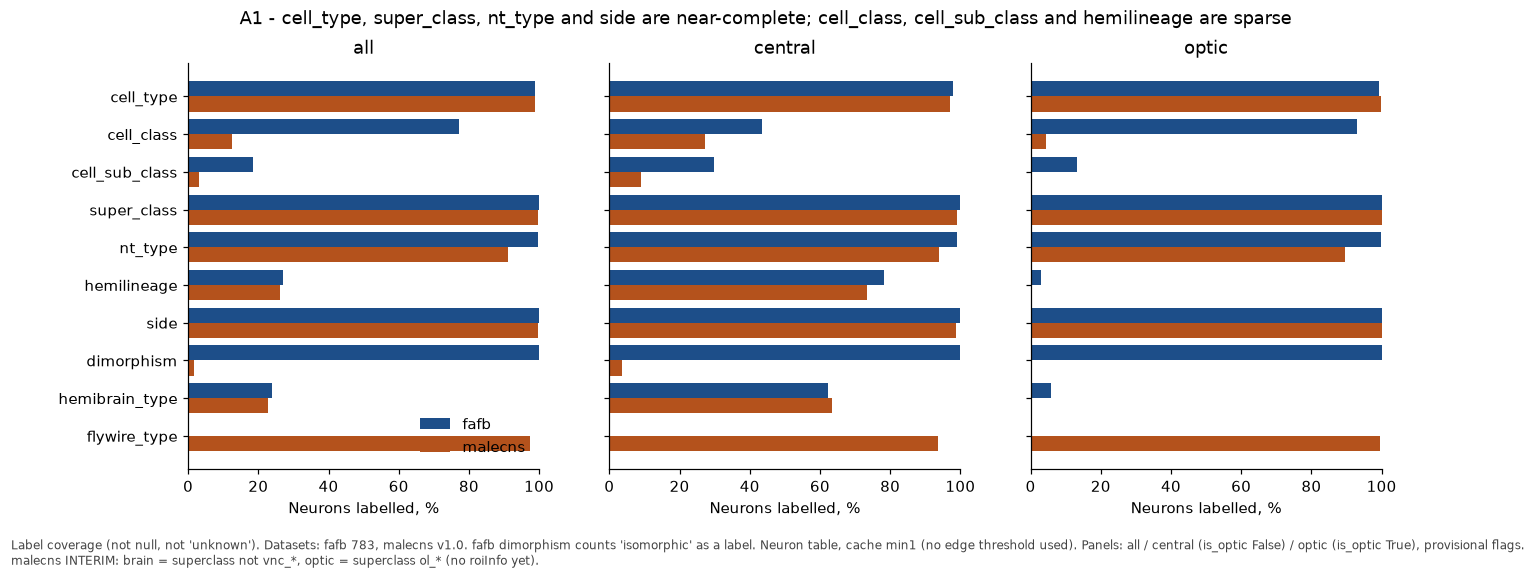

saved A1_fafb-malecns_783-v1.0_all-central-optic_min1.png


dataset          fafb                malecns               
population        all central  optic     all central  optic
column                                                     
cell_class       77.2    43.5   93.0    12.6    27.4    4.5
cell_sub_class   18.5    29.9   13.2     3.2     9.1    0.0
cell_type        98.9    97.9   99.3    98.9    96.9  100.0
dimorphism      100.0   100.0  100.0     1.6     3.5    0.5
flywire_type      NaN     NaN    NaN    97.5    93.6   99.6
hemibrain_type   23.9    62.3    5.8    22.7    63.4    0.4
hemilineage      27.0    78.1    2.9    26.1    73.4    0.1
nt_type          99.6    99.0   99.8    91.1    93.8   89.5
side            100.0    99.9  100.0    99.6    98.8  100.0
super_class     100.0   100.0  100.0    99.6    98.9  100.0

In [3]:
LABELS = ["cell_type", "cell_class", "cell_sub_class", "super_class", "nt_type", "hemilineage",
          "side", "dimorphism", "hemibrain_type", "flywire_type"]

def labelled(s):
    return s.notna() & (s.astype("string").str.strip().str.lower() != "unknown") & (s.astype("string").str.strip() != "")

rows = []
for k, d in D.items():
    for pop, p in pops(d).items():
        for c in LABELS:
            if c == "flywire_type" and k != "malecns":
                continue
            rows.append({"dataset": k, "population": pop, "column": c, "n": len(p),
                         "labelled_pct": 100 * labelled(p[c]).mean() if len(p) else np.nan})
A1 = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True)
for ax, pop in zip(axes, ["all", "central", "optic"]):
    sub = A1[A1.population == pop]
    y = np.arange(len(LABELS)); h = 0.8 / len(D)
    for i, k in enumerate(D):
        v = sub[sub.dataset == k].set_index("column")["labelled_pct"].reindex(LABELS)
        ax.barh(y + i * h, v, height=h, color=COL[k], label=k)
    ax.set_yticks(y + h * (len(D) - 1) / 2, LABELS); ax.invert_yaxis()
    ax.set_xlim(0, 100); ax.set_xlabel("Neurons labelled, %"); ax.set_title(pop)
axes[0].legend(frameon=False, loc="lower right")
fig.suptitle("A1 - cell_type, super_class, nt_type and side are near-complete; cell_class, cell_sub_class and hemilineage are sparse")
ds = list(D)
save(fig, "A1", ds, "all-central-optic",
     f"Label coverage (not null, not 'unknown'). Datasets: {', '.join(f'{k} {REL[k]}' for k in ds)}. "
     "fafb dimorphism counts 'isomorphic' as a label. Neuron table, cache min1 (no edge threshold used). Panels: all / central (is_optic False) / optic (is_optic True), provisional flags.")
A1.pivot_table(index="column", columns=["dataset", "population"], values="labelled_pct").round(1)

In [4]:
# Null count per column per dataset (all neurons), and the week 2 comparison
nulls = pd.DataFrame({k: d[[c for c in config.NEURON_SCHEMA]].isna().sum() for k, d in D.items()})
nulls_pct = (100 * nulls / pd.Series({k: len(d) for k, d in D.items()})).round(1)
display(pd.concat({"null count": nulls, "null %": nulls_pct}, axis=1))
week2 = {("fafb", "cell_class"): 23, ("malecns", "cell_class"): 85, ("fafb", "cell_sub_class"): 81,
         ("fafb", "hemilineage"): 73, ("malecns", "hemilineage"): 79}
cmp = [{"dataset": k, "column": c, "week2_missing_%": v, "now_missing_%": nulls_pct.loc[c, k]}
       for (k, c), v in week2.items() if k in D]
display(pd.DataFrame(cmp))
cen = fafb[fafb.super_class == "central"]
NUM["A1_fafb_superclass_central_celltype_pct"] = pct(labelled(cen.cell_type).mean())
NUM["A1_fafb_superclass_central_cellclass_pct"] = pct(labelled(cen.cell_class).mean())
print("fafb super_class == central:", NUM["A1_fafb_superclass_central_celltype_pct"], "% cell_type (expect ~98),",
      NUM["A1_fafb_superclass_central_cellclass_pct"], "% cell_class (expect ~43)")
NUM["A1_table"] = A1.round(1).to_dict("records")

null count         null %        
                     fafb malecns   fafb malecns
neuron_id               0       0    0.0     0.0
dataset                 0       0    0.0     0.0
release                 0       0    0.0     0.0
cell_type            1542    1610    1.1     1.1
cell_class          31744  126515   22.8    87.4
cell_sub_class     113435  140110   81.5    96.8
super_class             0       0    0.0     0.0
side                    0       0    0.0     0.0
region                  0       0    0.0     0.0
nt_type                 0       0    0.0     0.0
nt_confidence         616   12947    0.4     8.9
n_pre              139262       0  100.0     0.0
n_post             139262       0  100.0     0.0
flywire_type       139262    3588  100.0     2.5
manc_type          139262  141217  100.0    97.6
hemibrain_type     105991  111838   76.1    77.3
dimorphism             14  142457    0.0    98.4
status             138604       0   99.5     0.0
hemilineage        101720  107012   73.0    73.9
nt_known            51425  144757   36.9   100.0

,dataset,column,week2_missing_%,now_missing_%
0,fafb,cell_class,23,22.8
1,malecns,cell_class,85,87.4
2,fafb,cell_sub_class,81,81.5
3,fafb,hemilineage,73,73.0
4,malecns,hemilineage,79,73.9


fafb super_class == central: 99.6 % cell_type (expect ~98), 32.2 % cell_class (expect ~43)


## A2. Where each superclass sits
Neuron counts per (super_class, neuropil), raw (log colour) and as row shares. Neuropil = FlyWire base name (sides merged), grouped by provisional region_group.

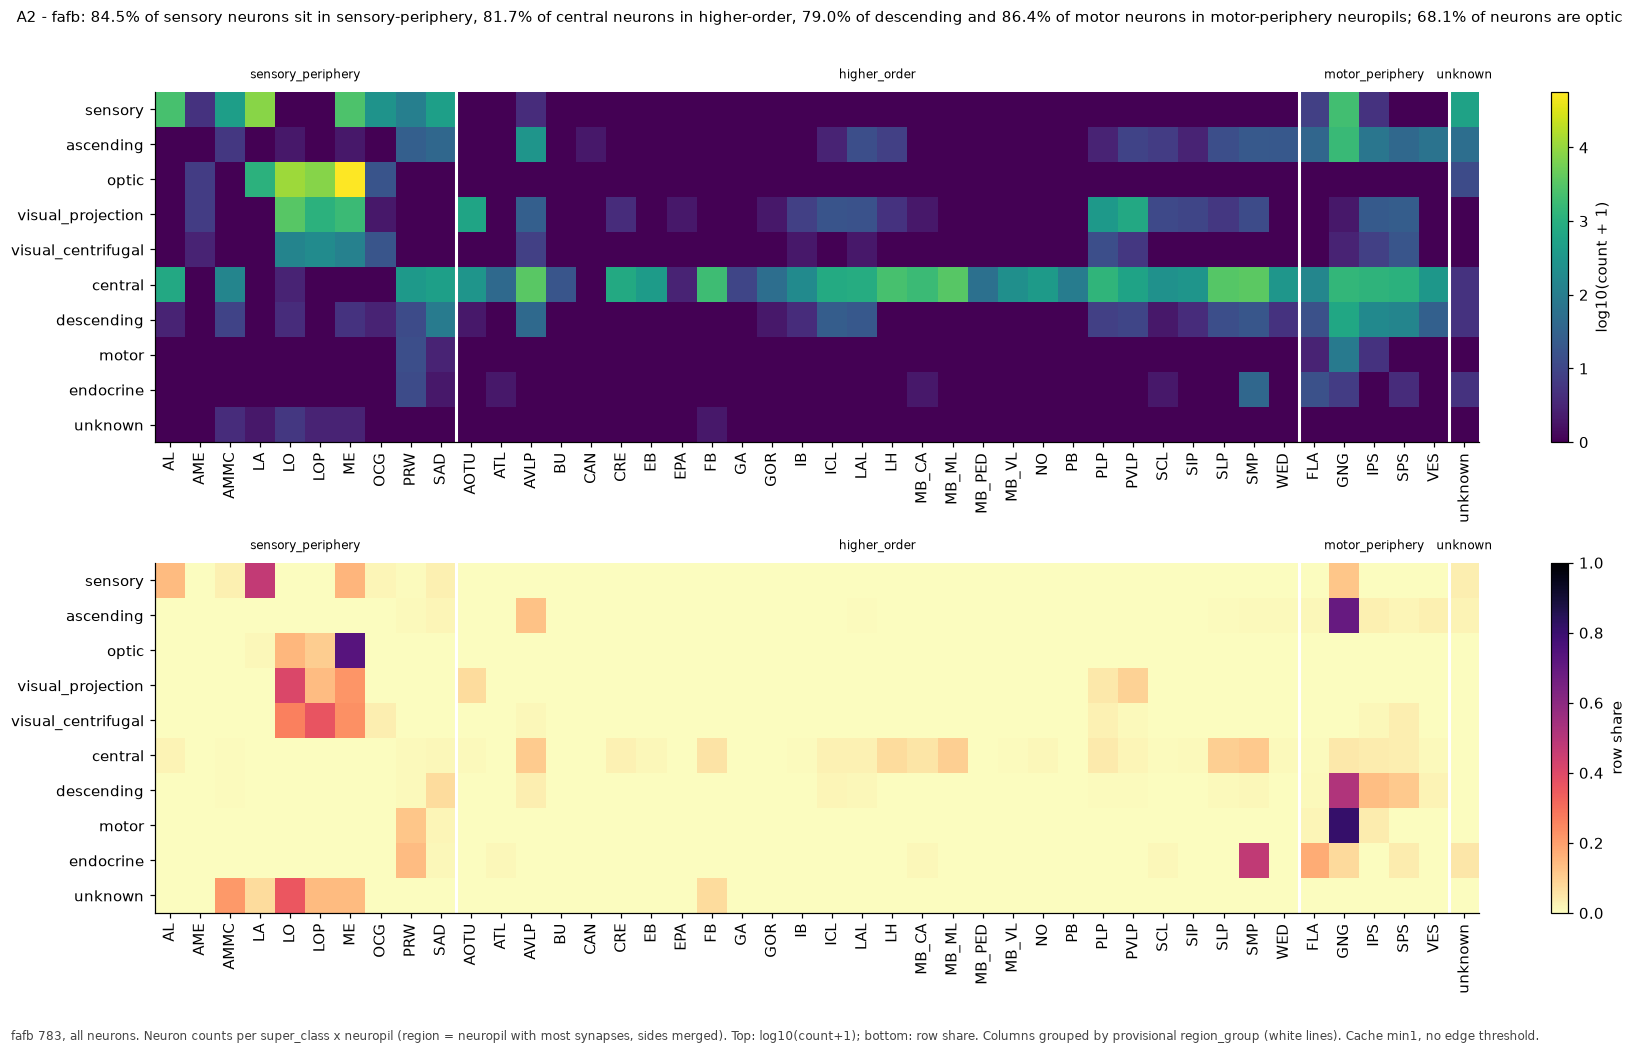

saved A2_fafb_783_all_min1.png
fafb GNG super_class mix: {'sensory': 0.349, 'ascending': 0.279, 'visual_projection': 0.0, 'visual_centrifugal': 0.0, 'central': 0.241, 'descending': 0.114, 'motor': 0.015, 'endocrine': 0.001}
A2 malecns skipped: no region yet (interim cache)


region_group,higher_order,motor_periphery,sensory_periphery,unknown
super_class,,,,
ascending,0.17,0.78,0.03,0.02
central,0.82,0.13,0.05,0.00
descending,0.11,0.79,0.10,0.00
endocrine,0.51,0.29,0.15,0.05
motor,0.00,0.86,0.14,0.00
optic,0.00,0.00,1.00,0.00
sensory,0.00,0.12,0.85,0.03
unknown,0.07,0.00,0.93,0.00
visual_centrifugal,0.05,0.05,0.90,0.00


In [5]:
SC_ORDER = ["sensory", "ascending", "optic", "visual_projection", "visual_centrifugal", "central",
            "descending", "motor", "endocrine"]          # afferent -> intrinsic -> efferent (Guide 4)
GROUPS = ["sensory_periphery", "higher_order", "motor_periphery"]
cols = []
for g in GROUPS:
    cols += sorted(TABLE.index[TABLE.region_group == g])
cols += ["unknown"]

for k, d in D.items():
    if k == "malecns" and INTERIM_M:
        print("A2 malecns skipped: no region yet (interim cache)"); continue
    extra = [s for s in d.super_class.astype(str).unique() if s not in SC_ORDER + ["unknown"]]
    rows_ = SC_ORDER + sorted(extra) + ["unknown"]
    ct = pd.crosstab(d.super_class.astype(str), d.neuropil.astype(str)).reindex(index=rows_, columns=cols, fill_value=0)
    ct = ct.loc[:, ct.sum() > 0]
    share = ct.div(ct.sum(axis=1).replace(0, np.nan), axis=0)
    fig, axes = plt.subplots(2, 1, figsize=(15, 9))
    for ax, data, title, kw in [(axes[0], np.log10(ct + 1), "log10(count + 1)", {"cmap": "viridis"}),
                                (axes[1], share, "row share", {"cmap": "magma_r", "vmin": 0, "vmax": 1})]:
        im = ax.imshow(data.values, aspect="auto", **kw)
        ax.set_yticks(range(len(data.index)), data.index); ax.set_xticks(range(len(data.columns)), data.columns, rotation=90)
        fig.colorbar(im, ax=ax, fraction=0.02, label=title)
        # region_group separators
        grp = [TABLE.region_group.get(c, "unknown") for c in data.columns]
        for i in range(1, len(grp)):
            if grp[i] != grp[i - 1]:
                ax.axvline(i - 0.5, color="white", lw=2)
        pos = {}
        for i, g in enumerate(grp):
            pos.setdefault(g, []).append(i)
        for g, ii in pos.items():
            ax.text(np.mean(ii), -0.8, g, ha="center", va="bottom", fontsize=8)
    optic_share = pct(d.is_optic.mean())
    NUM[f"A2_{k}_optic_pct"] = optic_share
    NUM[f"A2_{k}_superclass_x_group"] = (pd.crosstab(d.super_class.astype(str), d.region_group.astype(str),
                                                    normalize="index").round(3).to_dict())
    xg = pd.crosstab(d.super_class.astype(str), d.region_group.astype(str), normalize="index")
    f_ = lambda sc, g: pct(xg.loc[sc, g]) if sc in xg.index and g in xg.columns else 0
    fig.suptitle(f"A2 - {k}: {f_('sensory', 'sensory_periphery')}% of sensory neurons sit in sensory-periphery, "
                 f"{f_('central', 'higher_order')}% of central neurons in higher-order, "
                 f"{f_('descending', 'motor_periphery')}% of descending and {f_('motor', 'motor_periphery')}% of motor "
                 f"neurons in motor-periphery neuropils; {optic_share}% of neurons are optic", y=1.01, fontsize=10)
    fig.tight_layout()
    save(fig, "A2", [k], "all",
         f"{k} {REL[k]}, all neurons{' (in_brain)' if k == 'malecns' else ''}. Neuron counts per super_class x neuropil "
         "(region = neuropil with most synapses, sides merged). Top: log10(count+1); bottom: row share. "
         "Columns grouped by provisional region_group (white lines). Cache min1, no edge threshold.")
    # GNG check promised in the neuropil review
    if "GNG" in ct.columns:
        g = ct["GNG"]; NUM[f"A2_{k}_GNG_mix"] = (g / g.sum()).round(3)[g > 0].to_dict()
        print(k, "GNG super_class mix:", NUM[f"A2_{k}_GNG_mix"])
pd.crosstab(fafb.super_class.astype(str), fafb.region_group.astype(str), normalize="index").round(2)

## A3. How big are cell types
Neurons per cell_type, ranked. A type is *optic* if most of its neurons have is_optic True, *central complex* if most sit in FB, EB, PB or NO.

fafb {'types': 8846, 'types_1_2': 4632, 'types_gt100': 149, 'gt100_optic': 132, 'largest': {'R1-6': 8452, 'KCg-m': 2189, 'T2a': 1772, 'Tm3': 1756, 'T4c': 1706}, 'cx_types': 219, 'cx_median_size': 5.0}
malecns {'types': 8638, 'types_1_2': 4486, 'types_gt100': 167, 'gt100_optic': 122, 'largest': {'Tm3': 2054, 'T3': 1940, 'T2a': 1872, 'L5': 1787, 'C3': 1779}, 'cx_types': 0, 'cx_median_size': None}


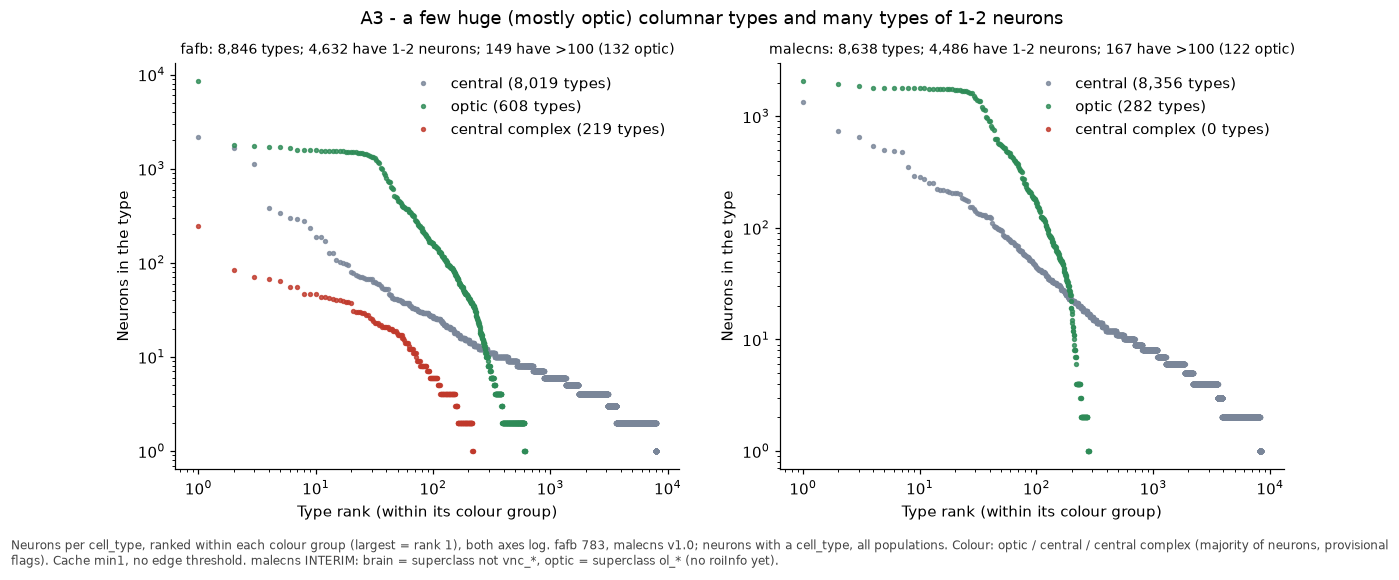

saved A3_fafb-malecns_783-v1.0_all_min1.png


In [6]:
CX = {"FB", "EB", "PB", "NO"}

def type_table(d):
    t = d[labelled(d.cell_type)].copy()
    g = t.groupby("cell_type", observed=True)
    out = pd.DataFrame({"n": g.size(), "optic_frac": g["is_optic"].mean(),
                        "cx_frac": g["neuropil"].apply(lambda s: s.isin(CX).mean()),
                        "region_group": g["region_group"].agg(lambda s: s.mode().iloc[0])})
    out["kind"] = np.where(out.cx_frac > 0.5, "central complex", np.where(out.optic_frac > 0.5, "optic", "central"))
    return out.sort_values("n", ascending=False)

TT = {k: type_table(d) for k, d in D.items()}
fig, axes = plt.subplots(1, len(D), figsize=(6.5 * len(D), 4.8), squeeze=False)
for ax, (k, t) in zip(axes[0], TT.items()):
    for kind in ["central", "optic", "central complex"]:
        s_ = t[t.kind == kind].n.values           # already sorted, largest first
        ax.plot(np.arange(1, len(s_) + 1), s_, "o", ms=2.5, color=TYPECOL[kind], label=f"{kind} ({len(s_):,} types)", alpha=0.8)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Type rank (within its colour group)"); ax.set_ylabel("Neurons in the type"); ax.legend(frameon=False)
    NUM[f"A3_{k}"] = {"types": len(t), "types_1_2": int((t.n <= 2).sum()), "types_gt100": int((t.n > 100).sum()),
                      "gt100_optic": int(((t.n > 100) & (t.kind == "optic")).sum()),
                      "largest": t.head(5).n.to_dict(),
                      "cx_types": int((t.kind == "central complex").sum()),
                      "cx_median_size": float(t[t.kind == "central complex"].n.median()) if (t.kind == "central complex").any() else None}
    a3 = NUM[f"A3_{k}"]
    ax.set_title(f"{k}: {a3['types']:,} types; {a3['types_1_2']:,} have 1-2 neurons; {a3['types_gt100']} have >100 ({a3['gt100_optic']} optic)", fontsize=9)
    print(k, a3)
fig.suptitle("A3 - a few huge (mostly optic) columnar types and many types of 1-2 neurons")
save(fig, "A3", list(D), "all",
     f"Neurons per cell_type, ranked within each colour group (largest = rank 1), both axes log. {', '.join(f'{k} {REL[k]}' for k in D)}; neurons with a cell_type, all populations. "
     "Colour: optic / central / central complex (majority of neurons, provisional flags). Cache min1, no edge threshold.")

## A4. Does each type sit under one superclass
`unknown` super_class is not counted as a value.

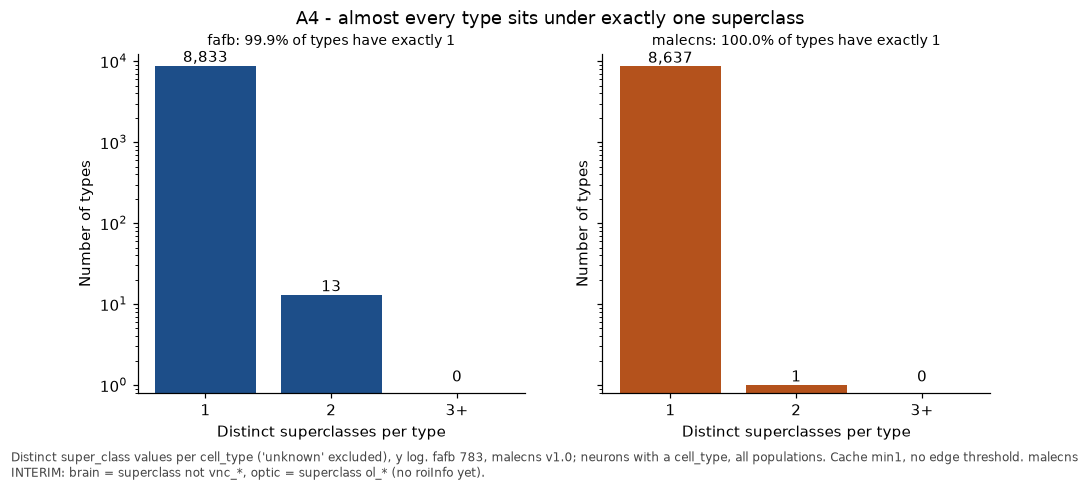

saved A4_fafb-malecns_783-v1.0_all_min1.png
{'fafb': 13, 'malecns': 1} types with >1 superclass -> reports/A4_multi_superclass_types.csv


,dataset,cell_type,super_class,neurons
0,fafb,DNg36_a,descending,3
1,fafb,DNg36_a,central,1
2,fafb,DNge102,descending,3
3,fafb,DNge102,central,1
4,fafb,LC20b,visual_projection,46
5,fafb,LC20b,optic,1
6,fafb,MTe02,visual_projection,74
7,fafb,MTe02,optic,1
8,fafb,MTe05,visual_projection,23
9,fafb,MTe05,optic,2


In [7]:
fig, axes = plt.subplots(1, len(D), figsize=(5 * len(D), 4), squeeze=False, sharey=True)
multi_all = []
for ax, (k, d) in zip(axes[0], D.items()):
    t = d[labelled(d.cell_type) & (d.super_class.astype(str) != "unknown")]
    nsc = t.groupby("cell_type", observed=True)["super_class"].nunique()
    bins = pd.cut(nsc, [0, 1, 2, np.inf], labels=["1", "2", "3+"]).value_counts().reindex(["1", "2", "3+"], fill_value=0)
    ax.bar(bins.index, bins.values, color=COL[k]); ax.set_yscale("log")
    for x, v in zip(bins.index, bins.values):
        ax.text(x, max(v, 1), f"{v:,}", ha="center", va="bottom")
    ax.set_ylim(bottom=0.8)
    ax.set_xlabel("Distinct superclasses per type"); ax.set_ylabel("Number of types")
    ax.set_title(f"{k}: {pct(bins['1'] / bins.sum())}% of types have exactly 1", fontsize=9)
    NUM[f"A4_{k}"] = bins.to_dict()
    multi = nsc[nsc > 1].index
    if len(multi):
        ct = (t[t.cell_type.isin(multi)].groupby(["cell_type", "super_class"], observed=True).size()
              .rename("neurons").reset_index())
        ct.insert(0, "dataset", k); multi_all.append(ct)
fig.suptitle("A4 - almost every type sits under exactly one superclass")
save(fig, "A4", list(D), "all",
     f"Distinct super_class values per cell_type ('unknown' excluded), y log. {', '.join(f'{k} {REL[k]}' for k in D)}; "
     "neurons with a cell_type, all populations. Cache min1, no edge threshold.")
A4 = pd.concat(multi_all) if multi_all else pd.DataFrame(columns=["dataset", "cell_type", "super_class", "neurons"])
A4.to_csv(REP / "A4_multi_superclass_types.csv", index=False)
print(f"{A4.groupby('dataset').cell_type.nunique().to_dict()} types with >1 superclass -> reports/A4_multi_superclass_types.csv")
A4.head(20)

## A5. Left and right copies
Proposed homologue rule (draft, for D18): within a cell_type, pair left and right neurons one-to-one up to min(L, R);
the surplus neurons of the larger side are *unequal counts*. Neurons with side center/unknown or with no cell_type cannot be paired.
For splits, the whole type (both sides, paired or not) goes into the same fold, so unequal counts never put near-copies on both sides of a split.

fafb {'types_with_side': 8788, 'off_diagonal_pct': 23.5, 'off_diagonal_pct_optic': 47.4, 'off_diagonal_pct_central': 21.7, 'one_side_only': 123, 'paired_neurons': 132604, 'unpaired': {'side center': 90, 'side unknown': 29, 'no cell type': 1542, 'unequal counts': 4997}}
malecns {'types_with_side': 8569, 'off_diagonal_pct': 21.4, 'off_diagonal_pct_optic': 74.5, 'off_diagonal_pct_central': 19.6, 'one_side_only': 210, 'paired_neurons': 137654, 'unpaired': {'side center': 97, 'side unknown': 412, 'no cell type': 1610, 'unequal counts': 4984}}


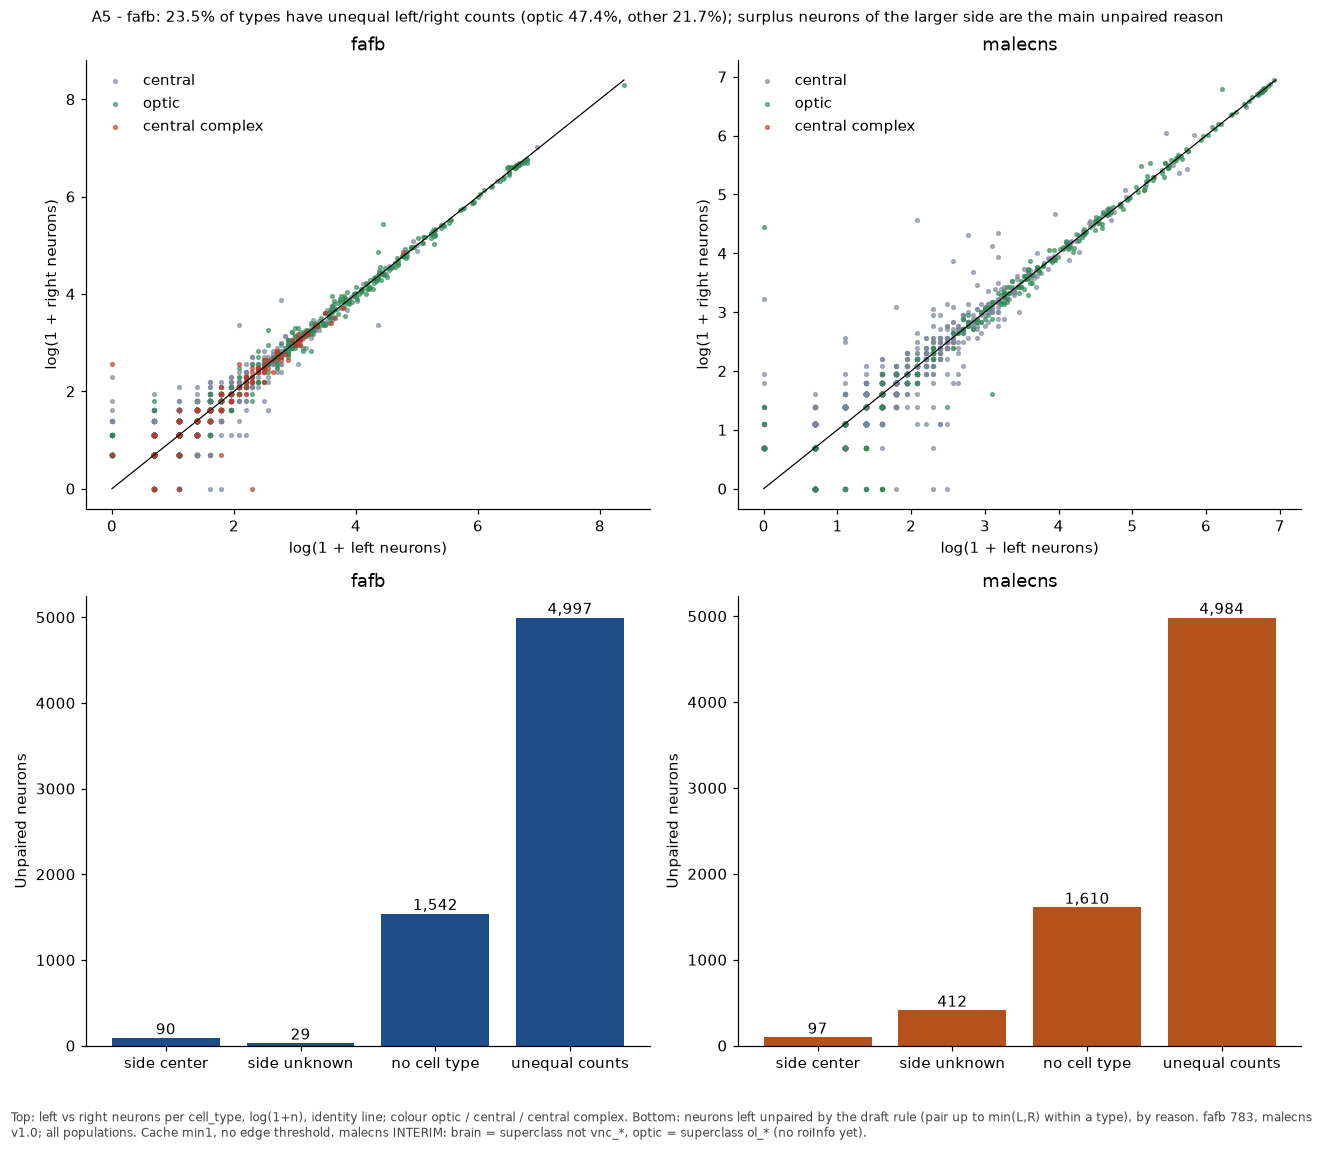

saved A5_fafb-malecns_783-v1.0_all_min1.png


In [8]:
fig, axes = plt.subplots(2, len(D), figsize=(6 * len(D), 10), squeeze=False)
for j, (k, d) in enumerate(D.items()):
    has_t = labelled(d.cell_type)
    lr = (d[has_t & d.side.isin(["left", "right"])].groupby(["cell_type", "side"], observed=True).size()
          .unstack(fill_value=0).reindex(columns=["left", "right"], fill_value=0))
    lr = lr.join(TT[k][["kind"]])
    ax = axes[0, j]
    for kind in ["central", "optic", "central complex"]:
        s = lr[lr.kind == kind]
        ax.scatter(np.log1p(s.left), np.log1p(s.right), s=6, alpha=0.6, color=TYPECOL[kind], label=kind)
    mx = np.log1p(lr[["left", "right"]].values.max()); ax.plot([0, mx], [0, mx], color="k", lw=0.8)
    ax.set_xlabel("log(1 + left neurons)"); ax.set_ylabel("log(1 + right neurons)"); ax.set_title(k); ax.legend(frameon=False)
    off = lr.left != lr.right
    reasons = pd.Series({
        "side center": int((has_t & (d.side == "center")).sum()),
        "side unknown": int((has_t & (d.side == "unknown")).sum()),
        "no cell type": int((~has_t).sum()),
        "unequal counts": int((lr.left - lr.right).abs().sum()),
    })
    ax = axes[1, j]
    ax.bar(reasons.index, reasons.values, color=COL[k]); ax.set_ylabel("Unpaired neurons"); ax.set_title(k)
    for x, v in zip(reasons.index, reasons.values):
        ax.text(x, v, f"{v:,}", ha="center", va="bottom")
    NUM[f"A5_{k}"] = {"types_with_side": len(lr), "off_diagonal_pct": pct(off.mean()),
                      "off_diagonal_pct_optic": pct(off[lr.kind == "optic"].mean()) if (lr.kind == "optic").any() else None,
                      "off_diagonal_pct_central": pct(off[lr.kind != "optic"].mean()),
                      "one_side_only": int(((lr.left == 0) | (lr.right == 0)).sum()),
                      "paired_neurons": int(2 * np.minimum(lr.left, lr.right).sum()),
                      "unpaired": reasons.to_dict()}
    print(k, NUM[f"A5_{k}"])
a5 = NUM["A5_fafb"]
fig.suptitle(f"A5 - fafb: {a5['off_diagonal_pct']}% of types have unequal left/right counts "
             f"(optic {a5['off_diagonal_pct_optic']}%, other {a5['off_diagonal_pct_central']}%); "
             f"surplus neurons of the larger side are the main unpaired reason", fontsize=10)
fig.tight_layout()
save(fig, "A5", list(D), "all",
     f"Top: left vs right neurons per cell_type, log(1+n), identity line; colour optic / central / central complex. "
     f"Bottom: neurons left unpaired by the draft rule (pair up to min(L,R) within a type), by reason. "
     f"{', '.join(f'{k} {REL[k]}' for k in D)}; all populations. Cache min1, no edge threshold.")

## A6. How much can be matched across datasets
Matched type = a fafb cell_type that appears in malecns.flywire_type (only through this column). Comma lists in flywire_type are split.

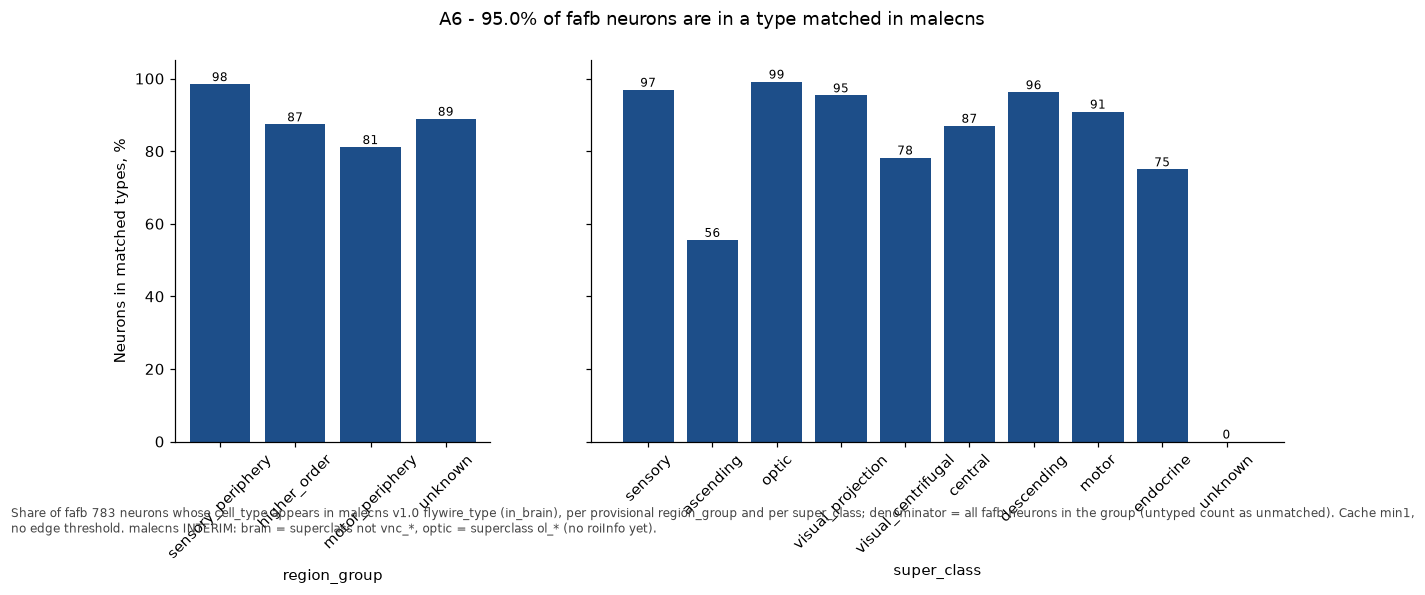

saved A6_fafb-malecns_783-v1.0_all_min1.png
{'A6_malecns_flywire_type_with_comma': 2751, 'A6_fafb_types': 8846, 'A6_fafb_matched_types': 7783, 'A6_fafb_neurons_in_matched_pct': 95.0, 'A6_by_region_group': {'sensory_periphery': 98.5, 'higher_order': 87.4, 'motor_periphery': 81.1, 'unknown': 88.9}, 'A6_by_super_class': {'sensory': 96.9, 'ascending': 55.5, 'optic': 99.2, 'visual_projection': 95.4, 'visual_centrifugal': 78.2, 'central': 87.0, 'descending': 96.2, 'motor': 90.9, 'endocrine': 75.0, 'unknown': 0.0}}


In [9]:
if HAS_M:
    ft = D["malecns"]["flywire_type"].dropna().astype(str)
    MATCHED = set(t.strip() for v in ft for t in v.split(",") if t.strip())
    NUM["A6_malecns_flywire_type_with_comma"] = int(ft.str.contains(",").sum())
    f = fafb[labelled(fafb.cell_type)].copy()
    f["matched"] = f.cell_type.astype(str).isin(MATCHED)
    NUM["A6_fafb_types"] = int(f.cell_type.nunique()); NUM["A6_fafb_matched_types"] = int(f.loc[f.matched, "cell_type"].nunique())
    allf = fafb.copy(); allf["matched"] = allf.cell_type.astype("string").isin(MATCHED).fillna(False)
    NUM["A6_fafb_neurons_in_matched_pct"] = pct(allf.matched.mean())
    by_g = 100 * allf.groupby("region_group").matched.mean().reindex(GROUPS + ["unknown"]).dropna()
    by_s = 100 * allf.groupby(allf.super_class.astype(str)).matched.mean()
    by_s = by_s.reindex([s for s in SC_ORDER + ["unknown"] if s in by_s.index])
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True, gridspec_kw={"width_ratios": [1, 2.2]})
    for ax, s, lab in [(axes[0], by_g, "region_group"), (axes[1], by_s, "super_class")]:
        ax.bar(s.index, s.values, color=COL["fafb"]); ax.set_xlabel(lab); ax.tick_params(axis="x", rotation=45)
        for x, v in zip(s.index, s.values):
            ax.text(x, v, f"{v:.0f}", ha="center", va="bottom", fontsize=8)
    axes[0].set_ylabel("Neurons in matched types, %"); axes[0].set_ylim(0, 105)
    NUM["A6_by_region_group"] = by_g.round(1).to_dict(); NUM["A6_by_super_class"] = by_s.round(1).to_dict()
    fig.suptitle(f"A6 - {NUM['A6_fafb_neurons_in_matched_pct']}% of fafb neurons are in a type matched in malecns")
    save(fig, "A6", ["fafb", "malecns"], "all",
         f"Share of fafb {REL['fafb']} neurons whose cell_type appears in malecns {REL['malecns']} flywire_type (in_brain), "
         "per provisional region_group and per super_class; denominator = all fafb neurons in the group (untyped count as unmatched). "
         "Cache min1, no edge threshold.")
    print({k: NUM[k] for k in NUM if k.startswith("A6")})
else:
    print("A6 needs the malecns cache - skipped")

## A7. Where sex-difference labels and unmatched types are
Brain regions only (fafb all; malecns in_brain). A type's region_group = the region_group of most of its neurons.

A7 (1) malecns panel skipped: no region yet (interim). malecns brain neurons with a dimorphism label: 2300 {'male-specific': 1227, 'sexually dimorphic': 765, 'potentially sexually dimorphic': 170, 'potentially male-specific': 138}


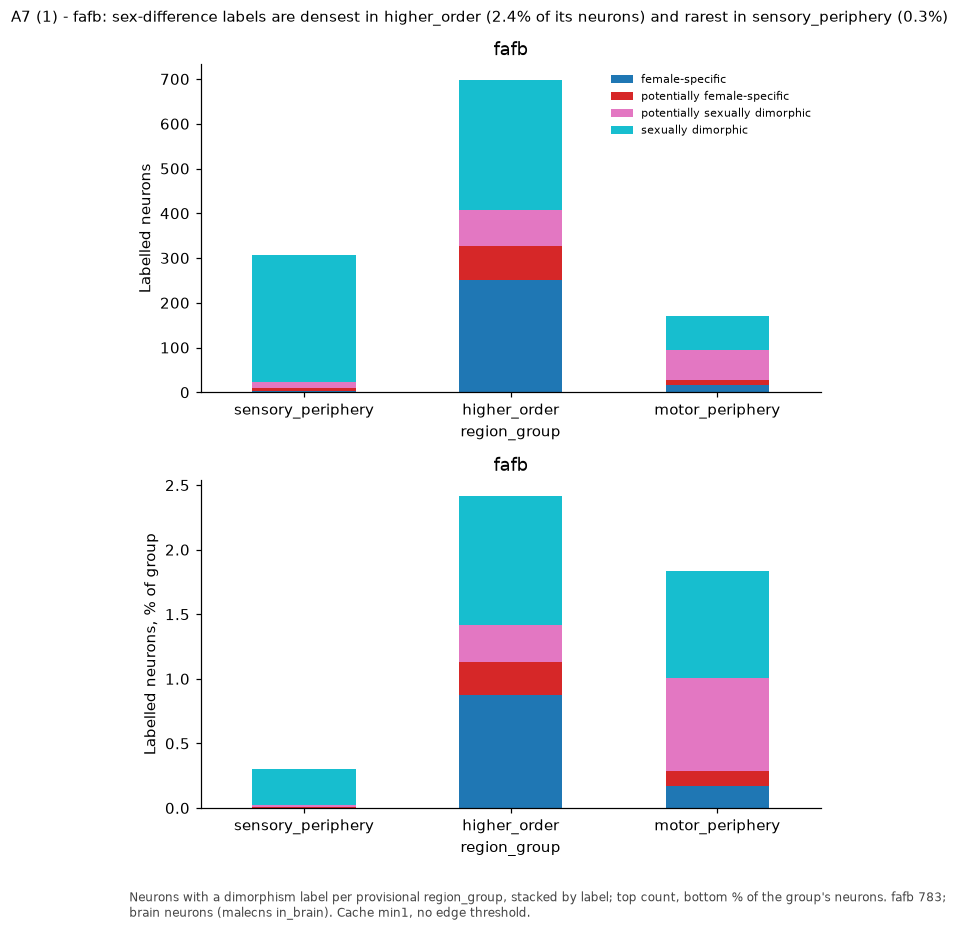

saved A7-1_fafb_783_brain_min1.png
{'A7_malecns_dimorphism_labelled': 2300, 'A7_fafb_dimorphism_labelled': 1176, 'A7_fafb_dimorphism_by_group': {'female-specific': {'sensory_periphery': 2, 'higher_order': 252, 'motor_periphery': 16}, 'potentially female-specific': {'sensory_periphery': 8, 'higher_order': 74, 'motor_periphery': 11}, 'potentially sexually dimorphic': {'sensory_periphery': 12, 'higher_order': 82, 'motor_periphery': 67}, 'sexually dimorphic': {'sensory_periphery': 285, 'higher_order': 290, 'motor_periphery': 77}}}


In [10]:
D7 = {k: d for k, d in D.items() if not (k == "malecns" and INTERIM_M)}
if HAS_M and INTERIM_M:
    NUM["A7_malecns_dimorphism_labelled"] = int(labelled(D["malecns"].dimorphism).sum())
    print("A7 (1) malecns panel skipped: no region yet (interim). malecns brain neurons with a dimorphism label:",
          NUM["A7_malecns_dimorphism_labelled"], D["malecns"].dimorphism.value_counts().to_dict())
fig, axes = plt.subplots(2, len(D7), figsize=(6.5 * len(D7), 8), squeeze=False)
for j, (k, d) in enumerate(D7.items()):
    # A sex-difference label = any dimorphism value except 'isomorphic' (isomorphic counts as labelled in A1 only)
    lab = d[labelled(d.dimorphism) & (d.dimorphism.astype("string").str.lower() != "isomorphic")]
    ct = pd.crosstab(lab.region_group.astype(str), lab.dimorphism.astype(str)).reindex(GROUPS + ["unknown"], fill_value=0)
    ct = ct.loc[ct.sum(axis=1) > 0] if ct.values.sum() else ct
    size = d.region_group.astype(str).value_counts().reindex(ct.index)
    for i, (data, ylab) in enumerate([(ct, "Labelled neurons"), (100 * ct.div(size, axis=0), "Labelled neurons, % of group")]):
        data.plot(kind="bar", stacked=True, ax=axes[i, j], legend=(i == 0), colormap="tab10", rot=0)
        axes[i, j].set_ylabel(ylab); axes[i, j].set_xlabel("region_group"); axes[i, j].set_title(k)
    if len(ct.columns):
        axes[0, j].legend(fontsize=7, frameon=False)
    NUM[f"A7_{k}_dimorphism_labelled"] = int(len(lab))
    NUM[f"A7_{k}_dimorphism_by_group"] = ct.to_dict()
sh = 100 * D["fafb"].pipe(lambda d: (labelled(d.dimorphism) & (d.dimorphism.astype("string").str.lower() != "isomorphic"))
                         .groupby(d.region_group.astype(str)).mean()).drop("unknown", errors="ignore")
fig.suptitle(f"A7 (1) - fafb: sex-difference labels are densest in {sh.idxmax()} ({sh.max():.1f}% of its neurons) "
             f"and rarest in {sh.idxmin()} ({sh.min():.1f}%)", fontsize=10)
fig.tight_layout()
save(fig, "A7-1", list(D7), "brain",
     f"Neurons with a dimorphism label per provisional region_group, stacked by label; top count, bottom % of the group's neurons. "
     f"{', '.join(f'{k} {REL[k]}' for k in D7)}; brain neurons (malecns in_brain). Cache min1, no edge threshold.")
print({k: NUM[k] for k in NUM if k.startswith("A7")})

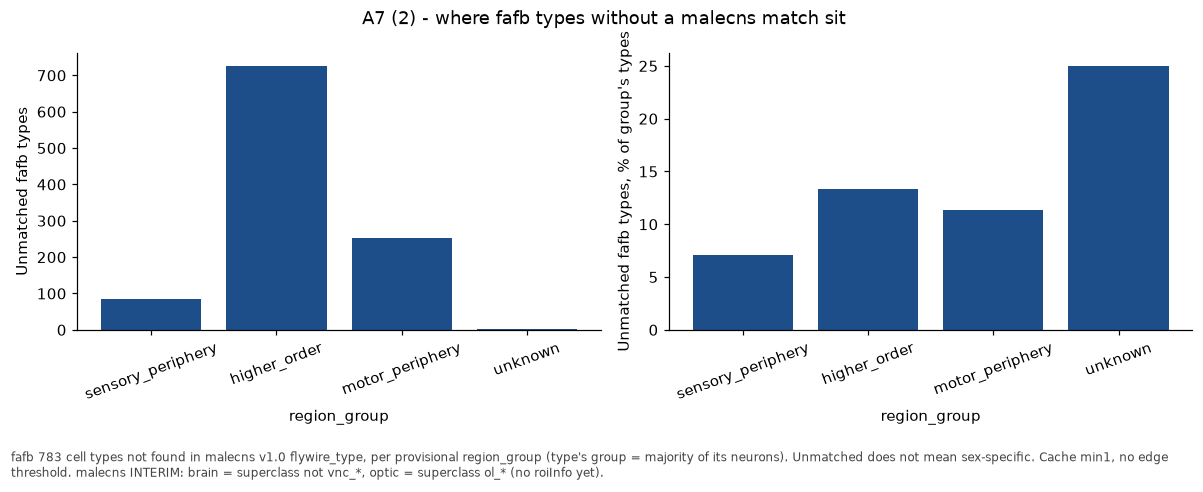

saved A7-2_fafb-malecns_783-v1.0_brain_min1.png
{'sensory_periphery': 84, 'higher_order': 726, 'motor_periphery': 252, 'unknown': 1} {'sensory_periphery': 7.1, 'higher_order': 13.4, 'motor_periphery': 11.3, 'unknown': 25.0}


In [11]:
if HAS_M:
    t = TT["fafb"].copy(); t["matched"] = t.index.astype(str).isin(MATCHED)
    un = t[~t.matched].groupby("region_group").size().reindex(GROUPS + ["unknown"], fill_value=0)
    tot = t.groupby("region_group").size().reindex(un.index)
    share = 100 * un / tot
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].bar(un.index, un.values, color=COL["fafb"]); axes[0].set_ylabel("Unmatched fafb types")
    axes[1].bar(share.index, share.values, color=COL["fafb"]); axes[1].set_ylabel("Unmatched fafb types, % of group's types")
    for ax in axes:
        ax.set_xlabel("region_group"); ax.tick_params(axis="x", rotation=20)
    NUM["A7_unmatched_types_by_group"] = un.to_dict(); NUM["A7_unmatched_types_pct_by_group"] = share.round(1).to_dict()
    fig.suptitle("A7 (2) - where fafb types without a malecns match sit")
    fig.tight_layout()
    save(fig, "A7-2", ["fafb", "malecns"], "brain",
         f"fafb {REL['fafb']} cell types not found in malecns {REL['malecns']} flywire_type, per provisional region_group "
         "(type's group = majority of its neurons). Unmatched does not mean sex-specific. Cache min1, no edge threshold.")
    print(NUM["A7_unmatched_types_by_group"], NUM["A7_unmatched_types_pct_by_group"])
else:
    print("A7 plot 2 needs the malecns cache - skipped")

## Numbers for the summary

In [12]:
(REP / "eda_A_numbers.json").write_text(json.dumps(NUM, indent=1, default=str), encoding="utf-8")
print("wrote reports/eda_A_numbers.json;", len(NUM), "entries")
print(sorted(p.name for p in FIG.glob("A*.png")))

wrote reports/eda_A_numbers.json; 27 entries
['A1_fafb-malecns_783-v1.0_all-central-optic_min1.png', 'A1_fafb_783_all-central-optic_min1.png', 'A2_fafb_783_all_min1.png', 'A3_fafb-malecns_783-v1.0_all_min1.png', 'A3_fafb_783_all_min1.png', 'A4_fafb-malecns_783-v1.0_all_min1.png', 'A4_fafb_783_all_min1.png', 'A5_fafb-malecns_783-v1.0_all_min1.png', 'A5_fafb_783_all_min1.png', 'A6_fafb-malecns_783-v1.0_all_min1.png', 'A7-1_fafb_783_brain_min1.png', 'A7-2_fafb-malecns_783-v1.0_brain_min1.png']
